# Optimized Logistic Regression — Financial Sentiment Classification

## Objective

This notebook develops and optimizes a TF-IDF-based Logistic Regression classifier for financial sentiment analysis using the FinancialPhraseBank dataset (66% annotator agreement subset).

The experiment focuses on improving classification performance through class balancing, regularization tuning, and feature representation optimization, followed by independent evaluation and error analysis.

## Methodology

- **Data:** Preprocessed FinancialPhraseBank training, validation, and test splits.
- **Model:** Class-weighted Logistic Regression with TF-IDF feature extraction.
- **Model selection:** Stratified five-fold cross-validation and GridSearchCV.
- **Optimization:** Regularization tuning (`C`), word-level, character-level, and combined TF-IDF representations, and character n-gram refinement.
- **Primary metric:** Macro-averaged F1-score.
- **Additional metrics:** Accuracy, class-level precision, recall, F1-score, and confusion matrix.
- **Error analysis:** Quantitative analysis of misclassification patterns and prediction confidence.
- **Final evaluation:** Assessment of the selected model on an untouched test set.

TF-IDF feature extraction is incorporated within scikit-learn pipelines to prevent data leakage during cross-validation.

# Imports

In [1]:
# General utilities
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Feature extraction and modeling
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Model selection
from sklearn.model_selection import StratifiedKFold, cross_validate

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Model persistence
import joblib

### Configuration and Dataset Loading

Class mapping, dataset paths & cross validation settings. The training dataset will be used for model fitting and stratified cross validation. The validation dataset remains separate and will only be used after model selection to evaluate generalization and inspect classification errors.

In [4]:
RANDOM_STATE = 42
N_SPLITS = 5

LABELS = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

CLASS_ORDER = [0, 1, 2]

TEXT_COL = "sentence_clean"
TARGET_COL = "label"

DATA_DIR = Path("Financial Phrasebank Project/data/splits")
RESULTS_DIR = Path("results/targeted_logreg")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "train.csv")
validation_df = pd.read_csv(DATA_DIR / "validation.csv")

print(f"Training samples: {len(train_df)}")
print(f"Validation samples: {len(validation_df)}")

display(train_df.head())

Training samples: 2947
Validation samples: 632


,sentence,label,sentence_clean
0,The biggest sellers in the chain 's supermarke...,1,The biggest sellers in the chain 's supermarke...
1,The Group 's revenue in 2008 amounted to EUR 9...,1,The Group 's revenue in 2008 amounted to EUR 9...
2,The brokerage said 2006 has seen a ` true turn...,2,The brokerage said 2006 has seen a ` true turn...
3,Pharmaceutical market in Netherlands Global Re...,1,Pharmaceutical market in Netherlands Global Re...
4,The investments and operational changes enable...,2,The investments and operational changes enable...


### Integrity checks
Check for required columns, missing values, valid sentiment labels, and duplicate cleaned sentences.

In [5]:
required_cols = {"sentence", "sentence_clean", "label"}

for name, df in [
    ("training", train_df),
    ("validation", validation_df)
]:
    # Check required columns
    assert required_cols.issubset(df.columns), (
        f"Missing columns in {name} dataset"
    )

    # Check missing values
    assert df[list(required_cols)].notna().all().all(), (
        f"Missing values in {name} dataset"
    )

    # Check labels
    assert set(df[TARGET_COL].unique()).issubset(CLASS_ORDER), (
        f"Unexpected labels in {name} dataset"
    )

    # Check duplicates
    assert not df[TEXT_COL].duplicated().any(), (
        f"Duplicate sentences in {name} dataset"
    )

print("Individual dataset checks passed.")

overlap = set(train_df[TEXT_COL]) & set(validation_df[TEXT_COL])

assert len(overlap) == 0, (
    f"Found {len(overlap)} overlapping sentences."
)

print("No overlapping cleaned sentences found.")

Individual dataset checks passed.
No overlapping cleaned sentences found.


- Inspect class distributions and class proportions

In [6]:
distribution = pd.DataFrame({
    "Training": train_df[TARGET_COL]
        .value_counts()
        .reindex(CLASS_ORDER, fill_value=0),

    "Validation": validation_df[TARGET_COL]
        .value_counts()
        .reindex(CLASS_ORDER, fill_value=0)
})

distribution.index = [
    LABELS[label] for label in CLASS_ORDER
]

display(distribution)

distribution_pct = (
    distribution
    .div(distribution.sum(axis=0), axis=1)
    * 100
)

display(distribution_pct.round(2))

,Training,Validation
negative,360,77
neutral,1770,379
positive,817,176


,Training,Validation
negative,12.22,12.18
neutral,60.06,59.97
positive,27.72,27.85


### Feature extraction with TF-IDF

The vectorizer uses unigram and bigram features to capture individual terms and adjacent word combinations. We are also filtering out extremely rare features.

In [7]:
tfidf_params = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "sublinear_tf": True
}

tfidf = TfidfVectorizer(**tfidf_params)

### Logistic Regression Model

The classifier learns a weighted mapping between TF-IDF features and financial sentiment labels. L2 regularization is retained to discourage excessively large coefficients and reduce overfitting.

We selected two configurations to be evaluated: standard Logistic Regression and class weighted Logistic Regression to investigate whether accounting for the observed class imbalance improves macro-F1 and minority class performance.

In [10]:
lr_params = {
    "max_iter": 1000,
    "C": 1.0,
    "solver": "lbfgs",
    "random_state": RANDOM_STATE
}

pipeline_standard = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_params)),
    ("classifier", LogisticRegression(
        **lr_params,
        class_weight=None
    ))
])

pipeline_balanced = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_params)),
    ("classifier", LogisticRegression(
        **lr_params,
        class_weight="balanced"
    ))
])

X_train = train_df[TEXT_COL]
y_train = train_df[TARGET_COL]

print("Training samples:", len(X_train))
print("Target classes:", sorted(y_train.unique()))

Training samples: 2947
Target classes: [np.int64(0), np.int64(1), np.int64(2)]


## Stratified Five Fold Cross Validation

We use stratification to maintain approximately equal sentiment class proportions across folds, ensuring that all three classes are represented during training and evaluation.

Both Logistic Regression configurations are evaluated using identical folds. The primary selection metric is macro-averaged F1-score, supplemented by accuracy and balanced accuracy.

In [11]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1_macro": "f1_macro"
}

cv_results = {}

models = {
    "Standard": pipeline_standard,
    "Balanced": pipeline_balanced
}

for name, pipeline in models.items():

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    cv_results[name] = scores

    print(f"{name} cross-validation completed.")

    fold_results = []

for name, scores in cv_results.items():
    for i in range(N_SPLITS):
        fold_results.append({
            "Model": name,
            "Fold": i + 1,
            "Accuracy": scores["test_accuracy"][i],
            "Balanced Accuracy": scores["test_balanced_accuracy"][i],
            "Macro-F1": scores["test_f1_macro"][i],
            "Train Macro-F1": scores["train_f1_macro"][i]
        })

fold_df = pd.DataFrame(fold_results)

display(fold_df.round(4))

Standard cross-validation completed.
Balanced cross-validation completed.


,Model,Fold,Accuracy,Balanced Accuracy,Macro-F1,Train Macro-F1
0,Standard,1,0.7966,0.6698,0.7172,0.8332
1,Standard,2,0.7492,0.5761,0.6141,0.8385
2,Standard,3,0.7742,0.6224,0.6675,0.8440
3,Standard,4,0.7572,0.5953,0.6396,0.8385
4,Standard,5,0.7657,0.6048,0.6488,0.8464
5,Balanced,1,0.8169,0.7858,0.7857,0.9505
6,Balanced,2,0.7814,0.7146,0.7230,0.9527
7,Balanced,3,0.7810,0.7183,0.7300,0.9555
8,Balanced,4,0.7861,0.7366,0.7326,0.9565
9,Balanced,5,0.7691,0.7025,0.7135,0.9594


### Model Performance Comparison

Performance is summarized using the mean and standard deviation of the evaluation metrics across five folds.

,mean_accuracy,mean_balanced_accuracy,mean_f1,std_f1,mean_train_f1,train_cv_gap
Model,,,,,,
Balanced,0.7869,0.7315,0.7370,0.0282,0.9549,0.2180
Standard,0.7686,0.6137,0.6574,0.0385,0.8401,0.1827


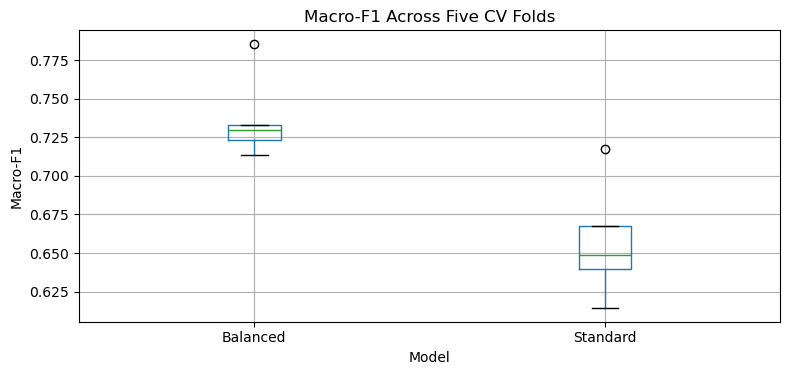

In [12]:
summary_df = (
    fold_df.groupby("Model")
    .agg(
        mean_accuracy=("Accuracy", "mean"),
        mean_balanced_accuracy=("Balanced Accuracy", "mean"),
        mean_f1=("Macro-F1", "mean"),
        std_f1=("Macro-F1", "std"),
        mean_train_f1=("Train Macro-F1", "mean")
    )
)

summary_df["train_cv_gap"] = (
    summary_df["mean_train_f1"]
    - summary_df["mean_f1"]
)

display(summary_df.round(4))

fig, ax = plt.subplots(figsize=(8, 4))

fold_df.boxplot(
    column="Macro-F1",
    by="Model",
    ax=ax
)

ax.set_title("Macro-F1 Across Five CV Folds")
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")

plt.suptitle("")
plt.tight_layout()
plt.show()

### Model selection
The configuration is selected according to the highest mean macro-F1 across stratified five-fold cross-validation.

In [13]:
best_model_name = summary_df["mean_f1"].idxmax()

best_pipeline = models[best_model_name]

print("Selected model:", best_model_name)
print(
    "Mean CV Macro-F1:",
    round(summary_df.loc[best_model_name, "mean_f1"], 4)
)

Selected model: Balanced
Mean CV Macro-F1: 0.737


## Train selected model and evaluate on validation data

The fitted model is evaluated on the independent validation dataset that was excluded from cross validation and model selection.

In [14]:
# Fit the selected pipeline using all training examples
best_pipeline.fit(X_train, y_train)

# Prepare the independent validation dataset
X_val = validation_df[TEXT_COL]
y_val = validation_df[TARGET_COL]

# Generate predictions
y_pred = best_pipeline.predict(X_val)

Validation Accuracy: 0.7911
Validation Macro-F1: 0.7326
              precision    recall  f1-score   support

    negative     0.6024    0.6494    0.6250        77
     neutral     0.8505    0.8707    0.8605       379
    positive     0.7453    0.6818    0.7122       176

    accuracy                         0.7911       632
   macro avg     0.7328    0.7340    0.7326       632
weighted avg     0.7910    0.7911    0.7905       632



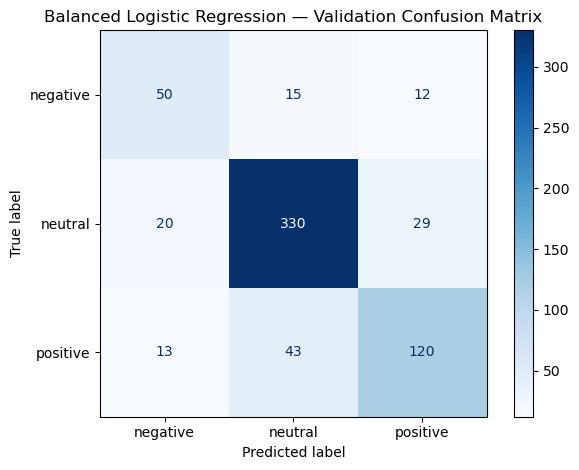

In [16]:
val_accuracy = accuracy_score(y_val, y_pred)
val_macro_f1 = f1_score(y_val, y_pred, average="macro")

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Macro-F1: {val_macro_f1:.4f}")

print(
    classification_report(
        y_val,
        y_pred,
        labels=CLASS_ORDER,
        target_names=[LABELS[i] for i in CLASS_ORDER],
        digits=4,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    labels=CLASS_ORDER,
    display_labels=[LABELS[i] for i in CLASS_ORDER],
    cmap="Blues",
    values_format="d"
)

plt.title("Balanced Logistic Regression — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## Error Taxonomy

This section investigates the classification errors made by the selected Logistic Regression model on the independent validation dataset.

We want to identify linguistic or domain-specific characteristics associated with incorrect predictions.

We are using the predictions where the model predicted the wrong category with high confidence

In [19]:
error_df = validation_df.copy()

error_df["predicted_label"] = y_pred

error_df["true_sentiment"] = (
    error_df[TARGET_COL].map(LABELS)
)

error_df["predicted_sentiment"] = (
    error_df["predicted_label"].map(LABELS)
)

# Get predicted class probabilities
probabilities = best_pipeline.predict_proba(X_val)

# Probability assigned to the predicted class
error_df["confidence"] = probabilities.max(axis=1)

# Identify incorrect predictions
error_df["is_error"] = (
    error_df[TARGET_COL] != error_df["predicted_label"]
)

errors_only = error_df[error_df["is_error"]].copy()

print("Total errors:", len(errors_only))

errors_only = errors_only.sort_values(
    "confidence",
    ascending=False
)

display(
    errors_only[
        [
            "sentence",
            "true_sentiment",
            "predicted_sentiment",
            "confidence"
        ]
    ].head(20)
)

Total errors: 132


,sentence,true_sentiment,predicted_sentiment,confidence
530,The company is well positioned in Brazil and U...,positive,neutral,0.848885
416,The company is also featured in the Ethibel Pi...,positive,neutral,0.804165
621,The core of Solidium 's investment strategy is...,positive,neutral,0.803253
610,- Among other Finnish shares traded in the US ...,neutral,negative,0.783579
281,The pipeline is strong .,positive,neutral,0.778661
210,"Pearl Plaza LLC , the joint venture of SRV and...",positive,neutral,0.759419
88,"After non-recurring items of EUR 177mn , profi...",neutral,negative,0.743444
573,Deliveries have started and the network will b...,positive,neutral,0.735904
277,They are also upset that some of the machinery...,negative,neutral,0.734709
14,The prosecutor is also demanding Outokumpu pay...,negative,neutral,0.723251


### Most common confusion categories
We analyze the following,
- error_count: How frequently that confusion occurs
- mean_confidence:	How strongly the model tends to favor its wrong predictions
- max_confidence: The highest-confidence wrong prediction within that confusion category

In [20]:
errors_only["confusion_type"] = (
    errors_only["true_sentiment"]
    + " → "
    + errors_only["predicted_sentiment"]
)

error_summary = (
    errors_only
    .groupby("confusion_type")
    .agg(
        error_count=("confidence", "size"),
        mean_confidence=("confidence", "mean"),
        max_confidence=("confidence", "max")
    )
    .sort_values("error_count", ascending=False)
)

display(error_summary.round(4))

,error_count,mean_confidence,max_confidence
confusion_type,,,
positive → neutral,43,0.5603,0.8489
neutral → positive,29,0.4780,0.6093
neutral → negative,20,0.4922,0.7836
negative → neutral,15,0.5130,0.7347
positive → negative,13,0.5245,0.7185
negative → positive,12,0.5439,0.6516


## Regularization Optimization

The initial class-weighted Logistic Regression model achieved strong training performance but substantially lower cross-validation performance, which could suggest potential overfitting. thus to investigate whether regularization can improve generalization, we evaluate several values of the inverse regularization parameter `C`.


In [23]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.01, 0.1, 0.5, 1, 2, 5, 10, 20, 50, 100]
}

grid_search = GridSearchCV(
    estimator=pipeline_balanced,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best C:", grid_search.best_params_)
print("Best CV Macro-F1:", round(grid_search.best_score_, 4))

grid_search.fit(X_train, y_train)

print("Best C:", grid_search.best_params_)
print("Best CV Macro-F1:", round(grid_search.best_score_, 4))

Best C: {'classifier__C': 10}
Best CV Macro-F1: 0.7444
Best C: {'classifier__C': 10}
Best CV Macro-F1: 0.7444


- Train the model with the best `C` value

In [24]:
baseline_cv_f1 = summary_df.loc["Balanced", "mean_f1"]

optimized_cv_f1 = grid_search.best_score_

comparison = pd.DataFrame({
    "Model": ["Original Balanced", "Tuned Balanced"],
    "CV Macro-F1": [
        baseline_cv_f1,
        optimized_cv_f1
    ]
})

display(comparison.round(4))

,Model,CV Macro-F1
0,Original Balanced,0.7370
1,Tuned Balanced,0.7444


## Feature Representation Optimization

Following regularization tuning, the class-weighted Logistic Regression classifier achieved its highest mean cross-validation macro-F1 of 0.7444 with `C=10`.

This experiment investigates whether alternative TF-IDF feature representations improve sentiment classification.

Three representations that we check are: word-level TF-IDF, character-level TF-IDF, and a combination of both, it basically allows us to work with different n-grams.

,Representation,Best C,CV Macro-F1
1,Character TF-IDF,50,0.7581
2,Combined TF-IDF,10,0.7554
0,Word TF-IDF,10,0.7444


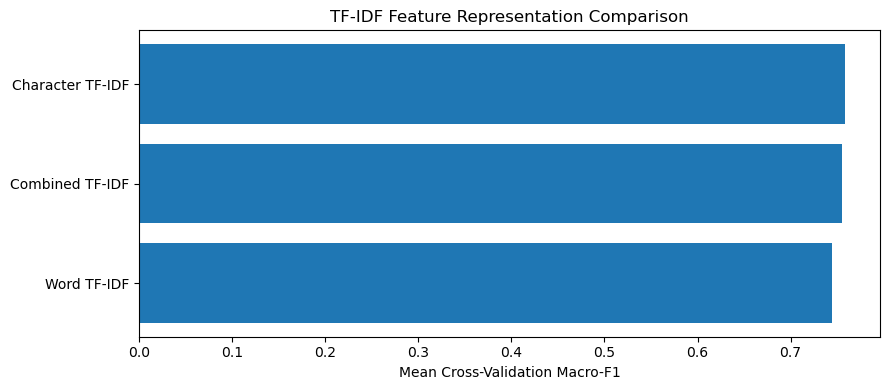

Best representation: Character TF-IDF
Best CV Macro-F1: 0.7581


In [25]:
from sklearn.pipeline import FeatureUnion

feature_extractors = {
    "Word TF-IDF": TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    ),

    "Character TF-IDF": TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True
    ),

    "Combined TF-IDF": FeatureUnion([
        ("word", TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("char", TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True
        ))
    ])
}

feature_pipelines = {}

for name, extractor in feature_extractors.items():

    feature_pipelines[name] = Pipeline([
        ("features", extractor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            solver="lbfgs",
            random_state=RANDOM_STATE
        ))
    ])

feature_param_grid = {
    "classifier__C": [1, 5, 10, 20, 50]
}

feature_results = []
feature_searches = {}

for name, pipeline in feature_pipelines.items():

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=feature_param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    feature_searches[name] = search

    feature_results.append({
        "Representation": name,
        "Best C": search.best_params_["classifier__C"],
        "CV Macro-F1": search.best_score_
    })

feature_summary = pd.DataFrame(feature_results)

display(
    feature_summary.sort_values(
        "CV Macro-F1",
        ascending=False
    ).round(4)
)

feature_summary_sorted = feature_summary.sort_values(
    "CV Macro-F1"
)

fig, ax = plt.subplots(figsize=(9, 4))

ax.barh(
    feature_summary_sorted["Representation"],
    feature_summary_sorted["CV Macro-F1"]
)

ax.set_xlabel("Mean Cross-Validation Macro-F1")
ax.set_title("TF-IDF Feature Representation Comparison")

plt.tight_layout()
plt.show()

best_feature_name = feature_summary.loc[
    feature_summary["CV Macro-F1"].idxmax(),
    "Representation"
]

best_feature_pipeline = feature_searches[
    best_feature_name
].best_estimator_

print("Best representation:", best_feature_name)
print(
    "Best CV Macro-F1:",
    round(
        feature_searches[best_feature_name].best_score_,
        4
    )
)

## Character Level Feature Refinement

Following feature representation comparison, character-level TF-IDF was selected as the provisional working representation.

Here we experiment with the sensitivity of classification performance to character n-gram length and Logistic Regression regularization.

In [26]:
character_pipeline = feature_pipelines["Character TF-IDF"]

character_param_grid = {
    "features__ngram_range": [
        (2, 4),
        (3, 5),
        (3, 6)
    ],
    "classifier__C": [
        10, 25, 50, 75, 100
    ]
}
 #run the cross validation
character_search = GridSearchCV(
    estimator=character_pipeline,
    param_grid=character_param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    return_train_score=True,
    refit=True
)

character_search.fit(X_train, y_train)

print("Best parameters:", character_search.best_params_)
print("Best CV Macro-F1:", round(character_search.best_score_, 4))

#view results

character_results = pd.DataFrame(
    character_search.cv_results_
)

character_summary = character_results[
    [
        "param_features__ngram_range",
        "param_classifier__C",
        "mean_train_score",
        "mean_test_score",
        "std_test_score"
    ]
].copy()

character_summary.columns = [
    "N-gram Range",
    "C",
    "Train Macro-F1",
    "CV Macro-F1",
    "CV Std"
]

display(
    character_summary
    .sort_values("CV Macro-F1", ascending=False)
    .round(4)
)

Best parameters: {'classifier__C': 25, 'features__ngram_range': (3, 6)}
Best CV Macro-F1: 0.7601


,N-gram Range,C,Train Macro-F1,CV Macro-F1,CV Std
5,"(3, 6)",25,1.0000,0.7601,0.0200
10,"(3, 5)",75,1.0000,0.7594,0.0212
11,"(3, 6)",75,1.0000,0.7590,0.0174
7,"(3, 5)",50,1.0000,0.7581,0.0185
14,"(3, 6)",100,0.9999,0.7576,0.0189
4,"(3, 5)",25,0.9999,0.7575,0.0190
13,"(3, 5)",100,1.0000,0.7561,0.0183
8,"(3, 6)",50,1.0000,0.7553,0.0168
1,"(3, 5)",10,0.9990,0.7549,0.0215
2,"(3, 6)",10,0.9992,0.7539,0.0231


## Validation Comparison: Baseline vs Optimized Model

Following regularization and feature representation optimization, character-level TF-IDF with 3–6 character n-grams and `C=25` achieved the highest mean cross-validation macro-F1 (0.7601).

However, the model also achieved nearly perfect training performance, suggesting a substantial generalization gap.

Thus, in this section we will compare the original class weighted baseline with the optimized character-level classifier on the independent validation dataset.

Pipeline(steps=[('features',
                 TfidfVectorizer(analyzer='char', min_df=2, ngram_range=(3, 6),
                                 sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(C=25, class_weight='balanced',
                                    max_iter=1000, random_state=42))])


,Model,Accuracy,Macro-F1
0,Original Baseline,0.7911,0.7326
1,Optimized Character TF-IDF,0.8070,0.7324


ORIGINAL BASELINE
              precision    recall  f1-score   support

    negative     0.6024    0.6494    0.6250        77
     neutral     0.8505    0.8707    0.8605       379
    positive     0.7453    0.6818    0.7122       176

    accuracy                         0.7911       632
   macro avg     0.7328    0.7340    0.7326       632
weighted avg     0.7910    0.7911    0.7905       632


OPTIMIZED CHARACTER MODEL
              precision    recall  f1-score   support

    negative     0.6197    0.5714    0.5946        77
     neutral     0.8607    0.9129    0.8860       379
    positive     0.7547    0.6818    0.7164       176

    accuracy                         0.8070       632
   macro avg     0.7450    0.7221    0.7324       632
weighted avg     0.8018    0.8070    0.8033       632



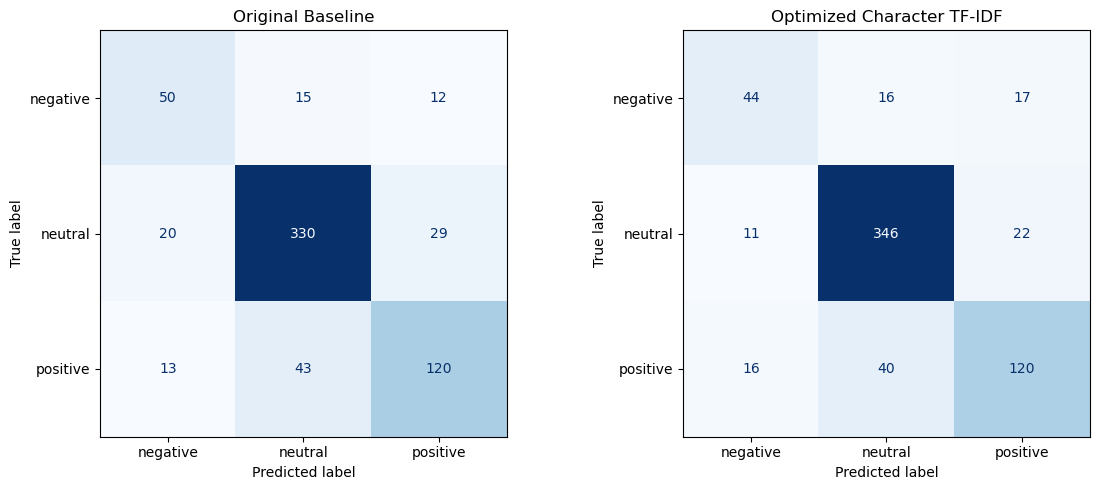

In [27]:
optimized_pipeline = character_search.best_estimator_

print(optimized_pipeline)

# Original balanced baseline
baseline_predictions = best_pipeline.predict(X_val)

# Optimized character-level model
optimized_predictions = optimized_pipeline.predict(X_val)

comparison_results = pd.DataFrame({
    "Model": [
        "Original Baseline",
        "Optimized Character TF-IDF"
    ],
    "Accuracy": [
        accuracy_score(y_val, baseline_predictions),
        accuracy_score(y_val, optimized_predictions)
    ],
    "Macro-F1": [
        f1_score(y_val, baseline_predictions, average="macro"),
        f1_score(y_val, optimized_predictions, average="macro")
    ]
})

display(comparison_results.round(4))

print("ORIGINAL BASELINE")
print(
    classification_report(
        y_val,
        baseline_predictions,
        target_names=[
            LABELS[i] for i in CLASS_ORDER
        ],
        digits=4
    )
)

print("\nOPTIMIZED CHARACTER MODEL")
print(
    classification_report(
        y_val,
        optimized_predictions,
        target_names=[
            LABELS[i] for i in CLASS_ORDER
        ],
        digits=4
    )
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, title in zip(
    axes,
    [baseline_predictions, optimized_predictions],
    ["Original Baseline", "Optimized Character TF-IDF"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        predictions,
        labels=CLASS_ORDER,
        display_labels=[
            LABELS[i] for i in CLASS_ORDER
        ],
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )

    ax.set_title(title)

plt.tight_layout()
plt.show()

## Final Model Evaluation on the Test Set

Following model optimization, the character-level TF-IDF Logistic Regression classifier was selected based on its highest training-only cross-validation macro-F1 (0.7601).

Although its validation accuracy improved compared with the original baseline, validation macro-F1 remained approximately unchanged. The optimized model achieved stronger neutral classification but lower negative-class recall.

The selected model configuration is now frozen and evaluated on the previously untouched test dataset.

In [28]:
test_df = pd.read_csv(DATA_DIR / "test.csv")

print("Test samples:", len(test_df))
display(test_df.head())

Test samples: 632


,sentence,label,sentence_clean
0,Subject-matter of the invention furthermore is...,1,Subject-matter of the invention furthermore is...
1,The figure does not include food exports from ...,1,The figure does not include food exports from ...
2,Raute reported a loss per share of EUR0 .86 fo...,0,Raute reported a loss per share of EUR0 .86 fo...
3,"In 2008 , Kemira recorded revenue of approxima...",1,"In 2008 , Kemira recorded revenue of approxima..."
4,This is the company 's first contract abroad .,1,This is the company 's first contract abroad .


Test-set overlap checks passed.
Test Accuracy: 0.8259
Test Macro-F1: 0.7678
              precision    recall  f1-score   support

    negative     0.7500    0.5844    0.6569        77
     neutral     0.8488    0.9158    0.8810       380
    positive     0.7963    0.7371    0.7656       175

    accuracy                         0.8259       632
   macro avg     0.7984    0.7458    0.7678       632
weighted avg     0.8222    0.8259    0.8217       632



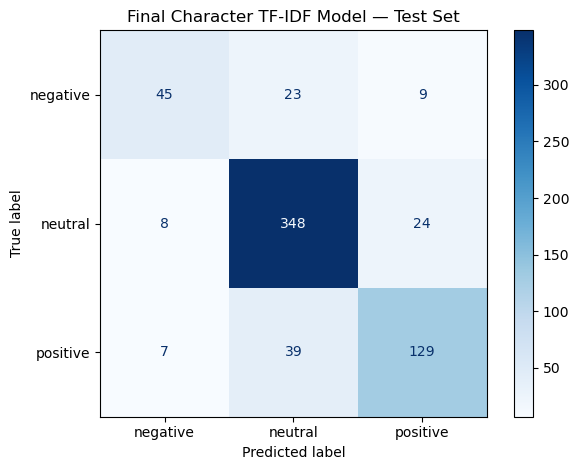

In [29]:
assert {TEXT_COL, TARGET_COL}.issubset(test_df.columns)
assert test_df[[TEXT_COL, TARGET_COL]].notna().all().all()
assert set(test_df[TARGET_COL].unique()).issubset(CLASS_ORDER)

train_sentences = set(train_df[TEXT_COL])
val_sentences = set(validation_df[TEXT_COL])
test_sentences = set(test_df[TEXT_COL])

assert not (test_sentences & train_sentences)
assert not (test_sentences & val_sentences)

print("Test-set overlap checks passed.")

final_model = character_search.best_estimator_

X_test = test_df[TEXT_COL]
y_test = test_df[TARGET_COL]

test_predictions = final_model.predict(X_test)

print(
    "Test Accuracy:",
    round(accuracy_score(y_test, test_predictions), 4)
)

print(
    "Test Macro-F1:",
    round(f1_score(y_test, test_predictions, average="macro"), 4)
)

print(
    classification_report(
        y_test,
        test_predictions,
        labels=CLASS_ORDER,
        target_names=[LABELS[i] for i in CLASS_ORDER],
        digits=4,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=CLASS_ORDER,
    display_labels=[LABELS[i] for i in CLASS_ORDER],
    cmap="Blues",
    values_format="d"
)

plt.title("Final Character TF-IDF Model — Test Set")
plt.tight_layout()
plt.show()


On the independent test set of 632 sentences, the model achieved 82.59% accuracy and a Macro-F1 of 0.7678, indicating reasonable generalization to unseen data.
Overall, character-level TF-IDF improved cross-validation performance, but improving negative class recall remains the main opportunity for future optimization, potentially through targeted data augmentation or more context-aware models.